In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress
import PyQt5
%matplotlib qt
import mne

MNE is an open source python package made for exploring, visualizing, and analyzing human neurophysiological data: MEG, EEG, sEEG, ECoG, NIRS, and more. [link to mne documentation](https://mne.tools/stable/index.html)

Ignorer MaxFilter signifie pas de SSS, pas de tSSS, pas de compensation du champ externe, pas de correction du mouvement. 

Donc OK pour analyses simples (PSD, time-frequency, ICA exploratoire) mais pas idéal pour source reconstruction ou analyses fines de topographie

In [2]:
raw = mne.io.read_raw_fif("/Users/elodiehusson/Desktop/run01.fif", preload=True, allow_maxshield=True)

Opening raw data file /Users/elodiehusson/Desktop/run01.fif...
    Read a total of 13 projection items:
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
    Range : 529000 ... 912999 =    529.000 ...   912.999 secs
Ready.


/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_79809/126410303.py:1: RuntimeWarning: This filename (/Users/elodiehusson/Desktop/run01.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif("/Users/elodiehusson/Desktop/run01.fif", preload=True, allow_maxshield=True)
/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_79809/126410303.py:1: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  raw = mne.io.read_raw_fif("/Users/elodiehusson/Desktop/run01.fif", preload=True, allow_maxshield=True)


Reading 0 ... 383999  =      0.000 ...   383.999 secs...


From the raw object, we can see that there are 306 data channels : 102 are magnetometers, and 204 are gradiometers. This is a normal protocol for MEG, we have 1 magn and 2 gradio for each position. So we have triplets. Sampling rate is at 1000 Hz, which is a normal rate : it give a good temporal resolution for the ERF / time-frequency. 

In [ ]:
raw.info

<Info | 26 non-empty values
 acq_pars: ACQactiveGround 0 ACQch.BIO001.gain 2000 ACQch.BIO001.highpass ...
 bads: []
 ch_names: BIO001, BIO002, BIO003, EXCI, IASX+, IASX-, IASY+, IASY-, IASZ+, ...
 chs: 3 BIO, 1 Flux excitation channel, 11 Internal Active Shielding data (Triux systems), 102 Magnetometers, 204 Gradiometers, 5 misc, 1 Stimulus, 1 System status channel information (Triux systems)
 custom_ref_applied: False
 description: TRIUX system at LaPitie
 dev_head_t: MEG device -> head transform
 dig: 231 items (3 Cardinal, 4 HPI, 224 Extra)
 events: 1 item (list)
 experimenter: Common User (acq)
 file_id: 4 items (dict)
 gantry_angle: 68.0
 highpass: 0.0 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 hpi_subsystem: 3 items (dict)
 line_freq: 50.0
 lowpass: 330.0 Hz
 maxshield: True
 meas_date: 2026-02-25 13:43:04 UTC
 meas_id: 4 items (dict)
 nchan: 328
 proc_history: 1 item (list)
 proj_id: 110
 proj_name: frint
 projs: generated with dossp-2.1: off, generated with dossp-2.1: off, ...
 sfreq: 1000.0 Hz
 subject_info: <subject_info | id: 1777, last_name: frint_pilote, first_name: p, birthday: 1980-01-01, sex: 1, hand: 1>
>

In [ ]:
mne.channel_indices_by_type(raw.info)

{'eeg': [],
 'csd': [],
 'stim': [326],
 'eog': [],
 'ecg': [],
 'emg': [],
 'misc': [321, 322, 323, 324, 325],
 'resp': [],
 'chpi': [],
 'exci': [3],
 'ias': [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 'syst': [327],
 'seeg': [],
 'dipole': [],
 'gof': [],
 'bio': [0, 1, 2],
 'ecog': [],
 'dbs': [],
 'temperature': [],
 'gsr': [],
 'ref_meg': [],
 'mag': [15,
  18,
  21,
  24,
  27,
  30,
  33,
  36,
  39,
  42,
  45,
  48,
  51,
  54,
  57,
  60,
  63,
  66,
  69,
  72,
  75,
  78,
  81,
  84,
  87,
  90,
  93,
  96,
  99,
  102,
  105,
  108,
  111,
  114,
  117,
  120,
  123,
  126,
  129,
  132,
  135,
  138,
  141,
  144,
  147,
  150,
  153,
  156,
  159,
  162,
  165,
  168,
  171,
  174,
  177,
  180,
  183,
  186,
  189,
  192,
  195,
  198,
  201,
  204,
  207,
  210,
  213,
  216,
  219,
  222,
  225,
  228,
  231,
  234,
  237,
  240,
  243,
  246,
  249,
  252,
  255,
  258,
  261,
  264,
  267,
  270,
  273,
  276,
  279,
  282,
  285,
  288,
  291,
  294,
  297,
  300,
  

Using matplotlib as 2D backend.


KeyboardInterrupt: 

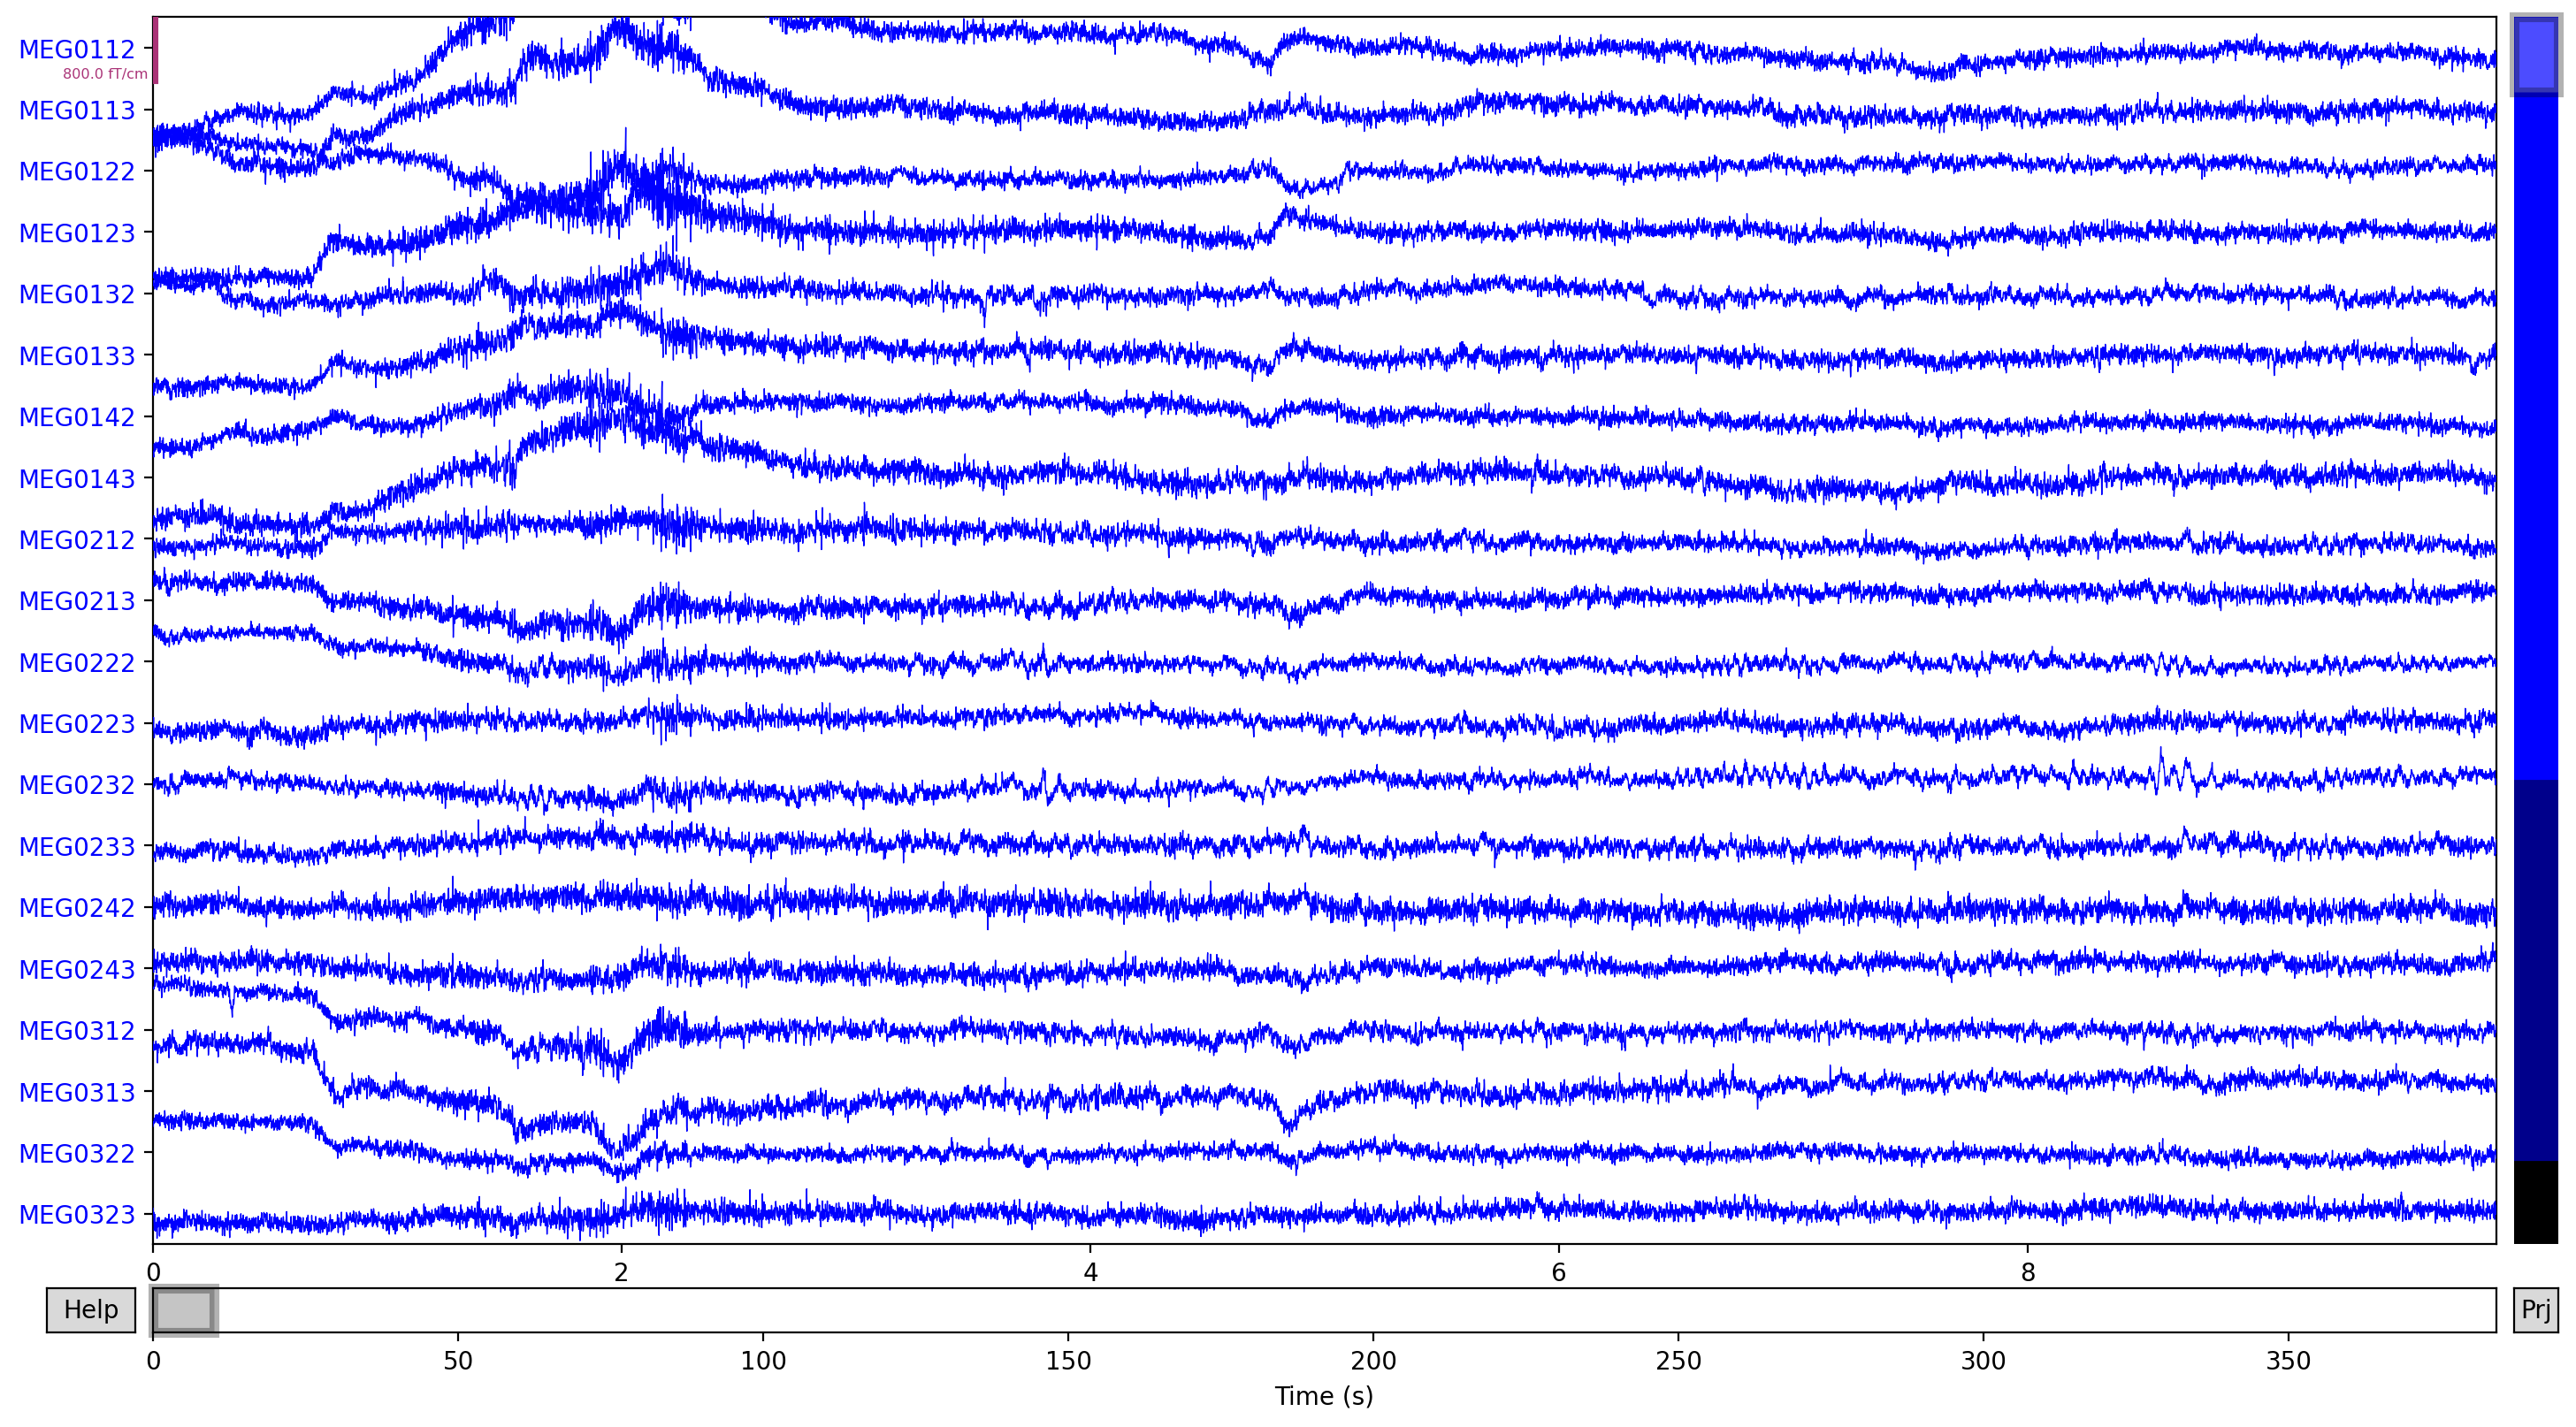

Channels marked as bad:
none


In [ ]:
raw.plot()

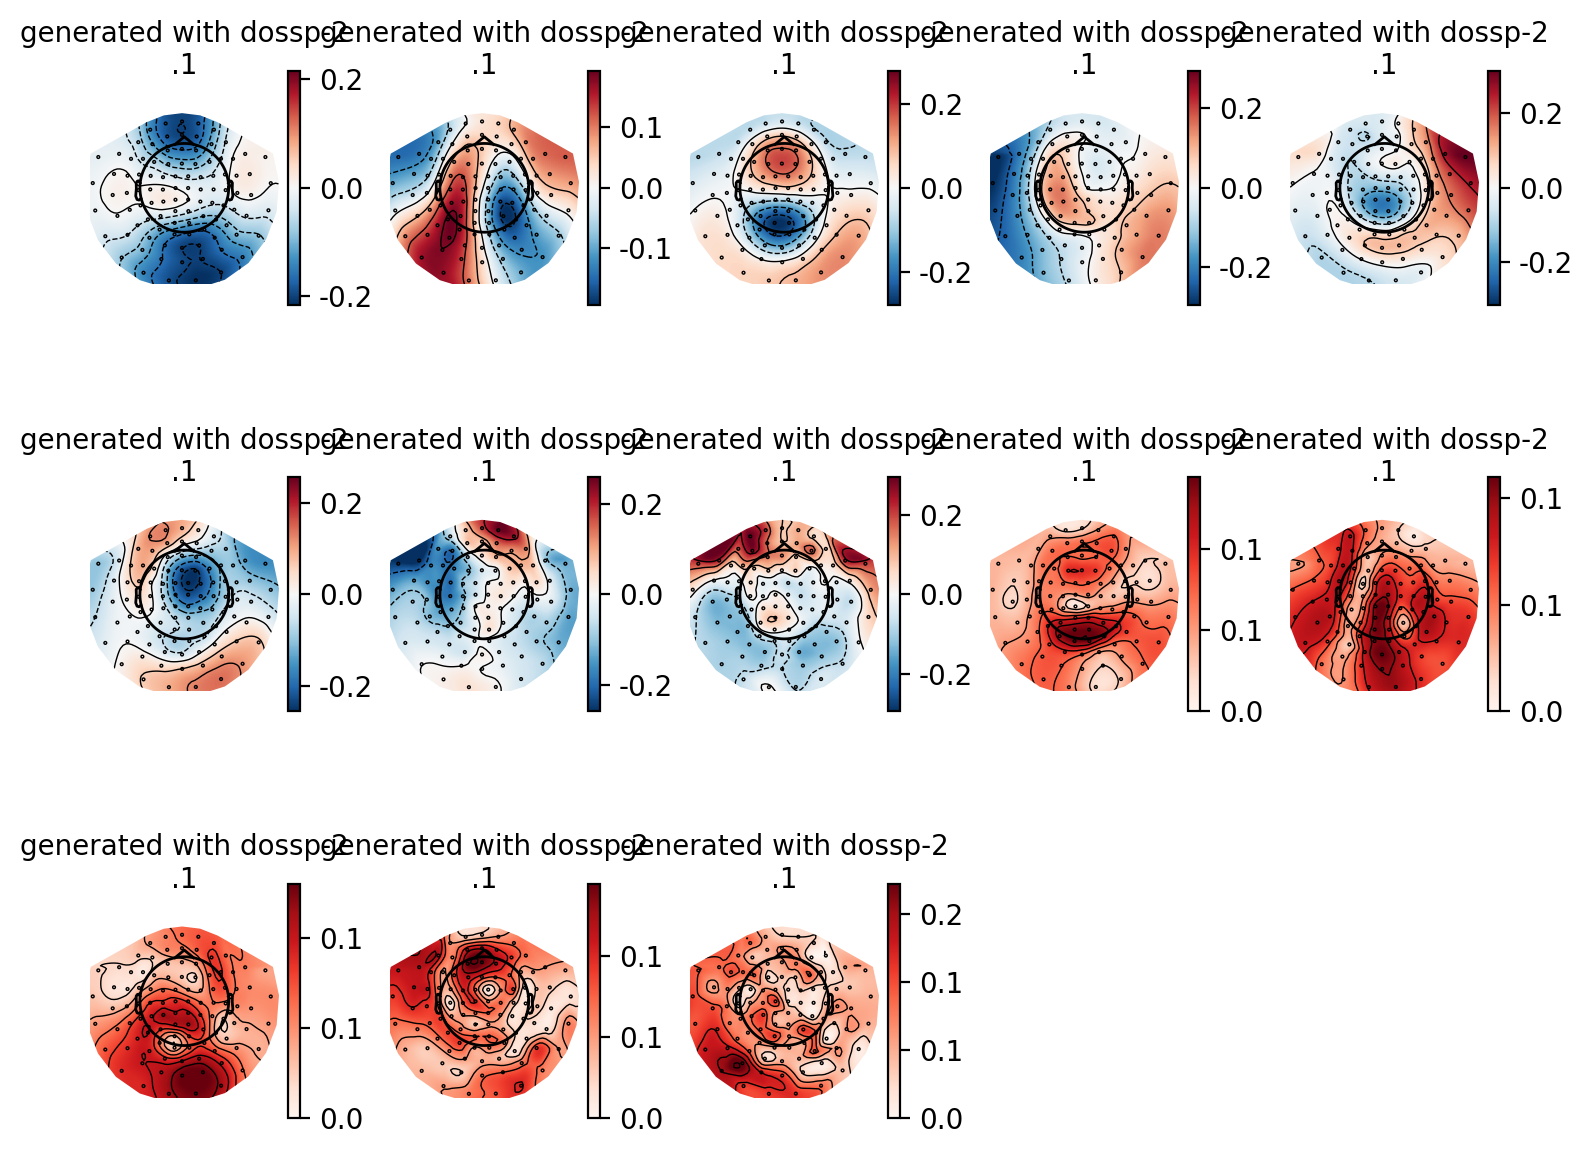

In [ ]:
raw.plot_projs_topomap(colorbar=True)

Effective window size : 2.048 (s)


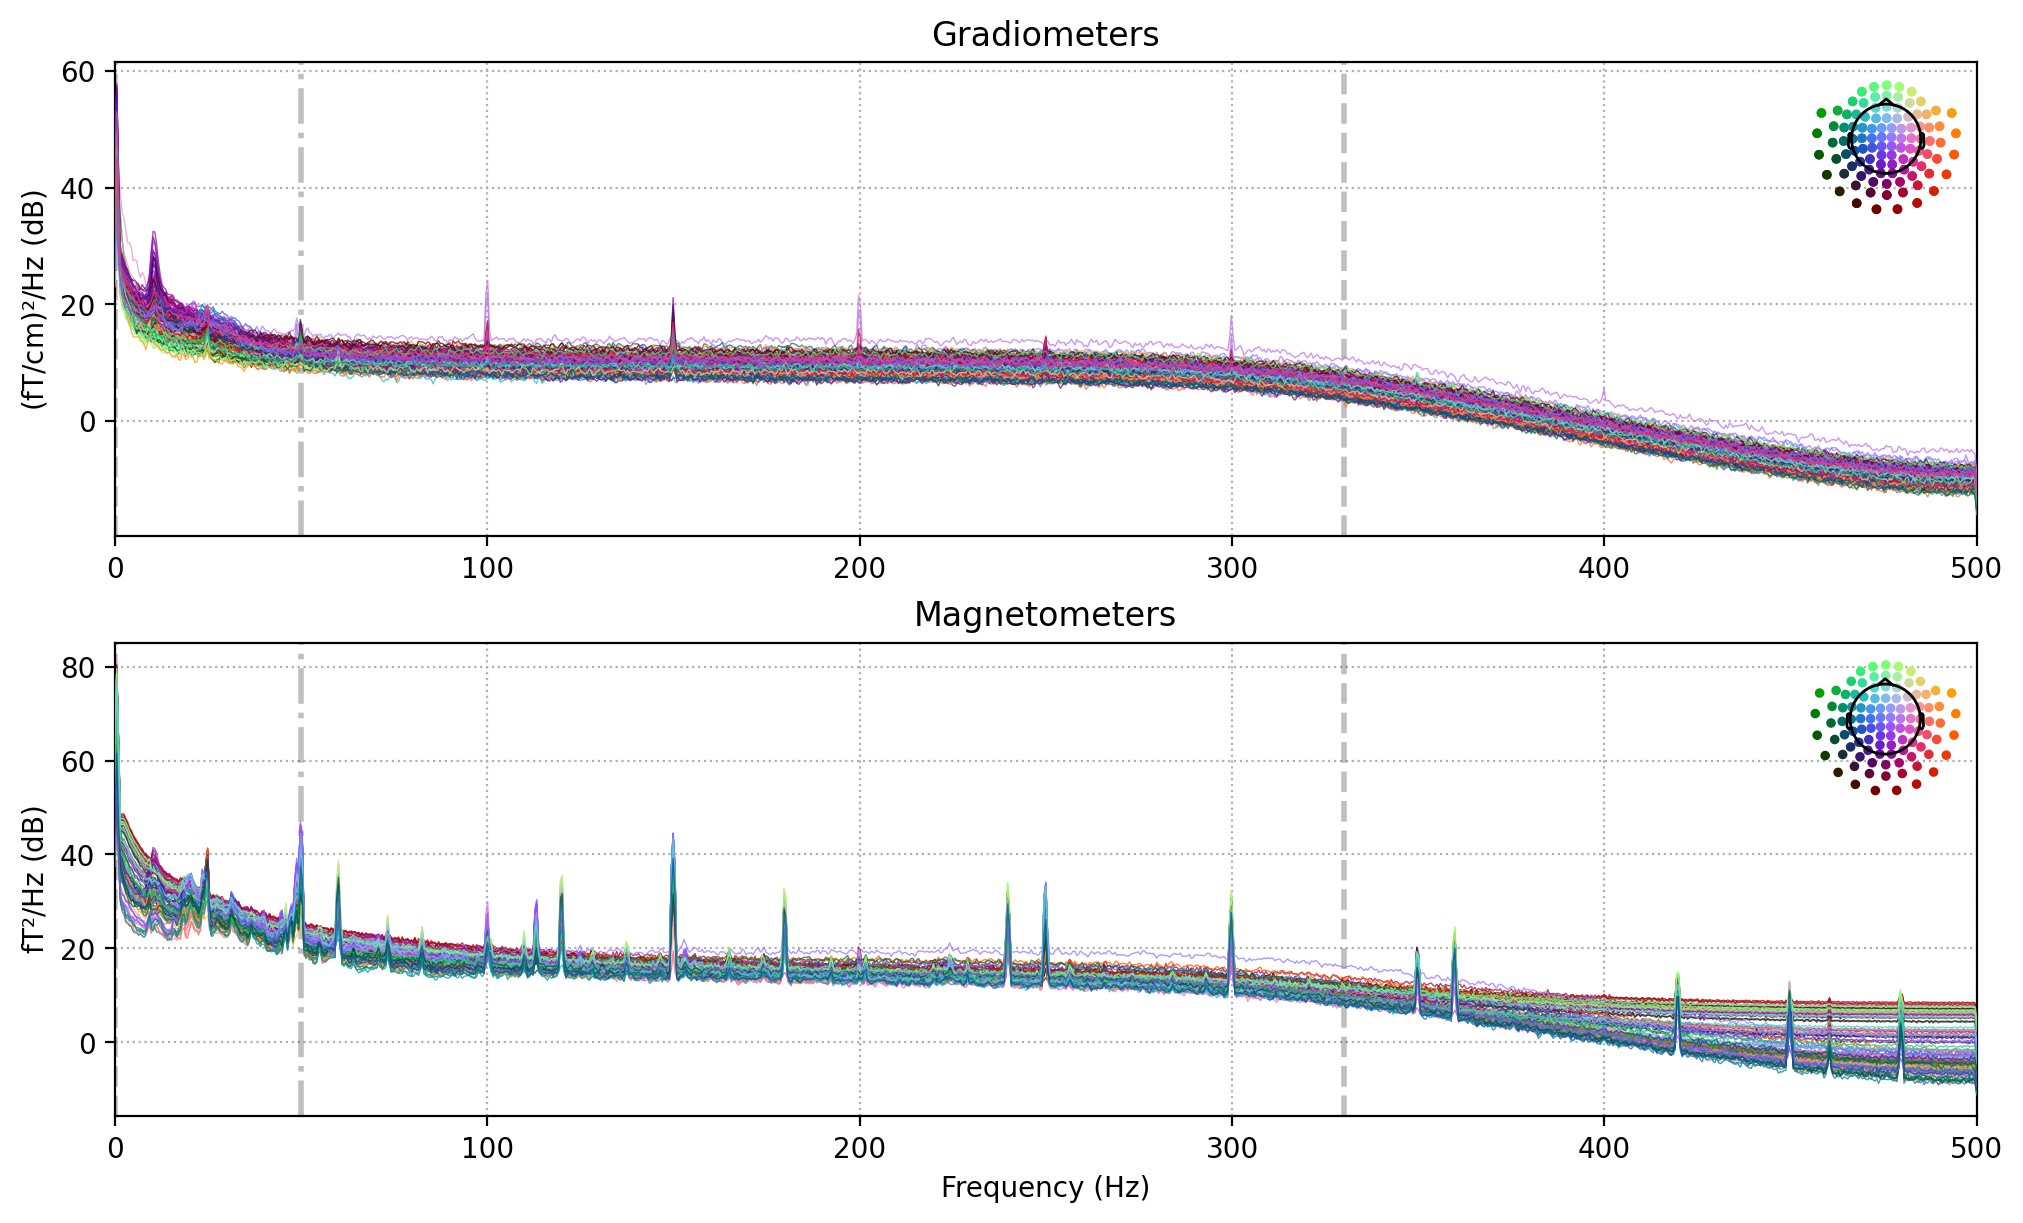

In [ ]:
raw.compute_psd().plot()

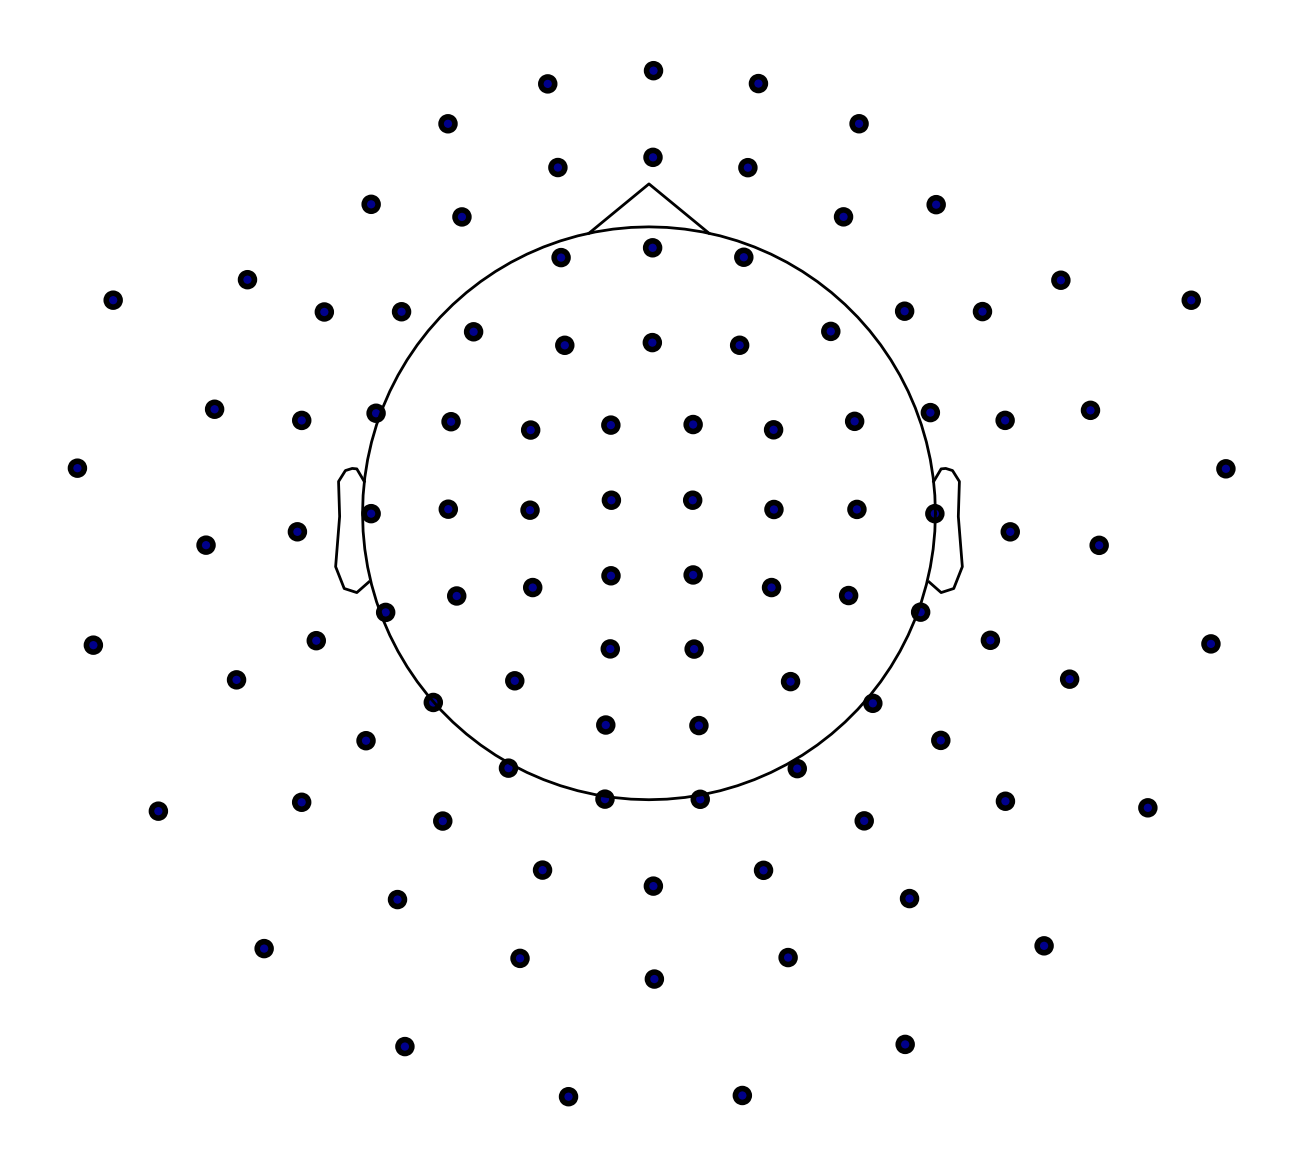

In [ ]:
raw.plot_sensors(ch_type="mag")

In [ ]:
mne.pick_types(raw.info, stim=True)

array([326])

## detecting artefacts

In [ ]:
ssp_projectors = raw.info["projs"]
raw.del_proj()

<Raw | run01.fif, 328 x 384000 (384.0 s), ~966.1 MB, data loaded>

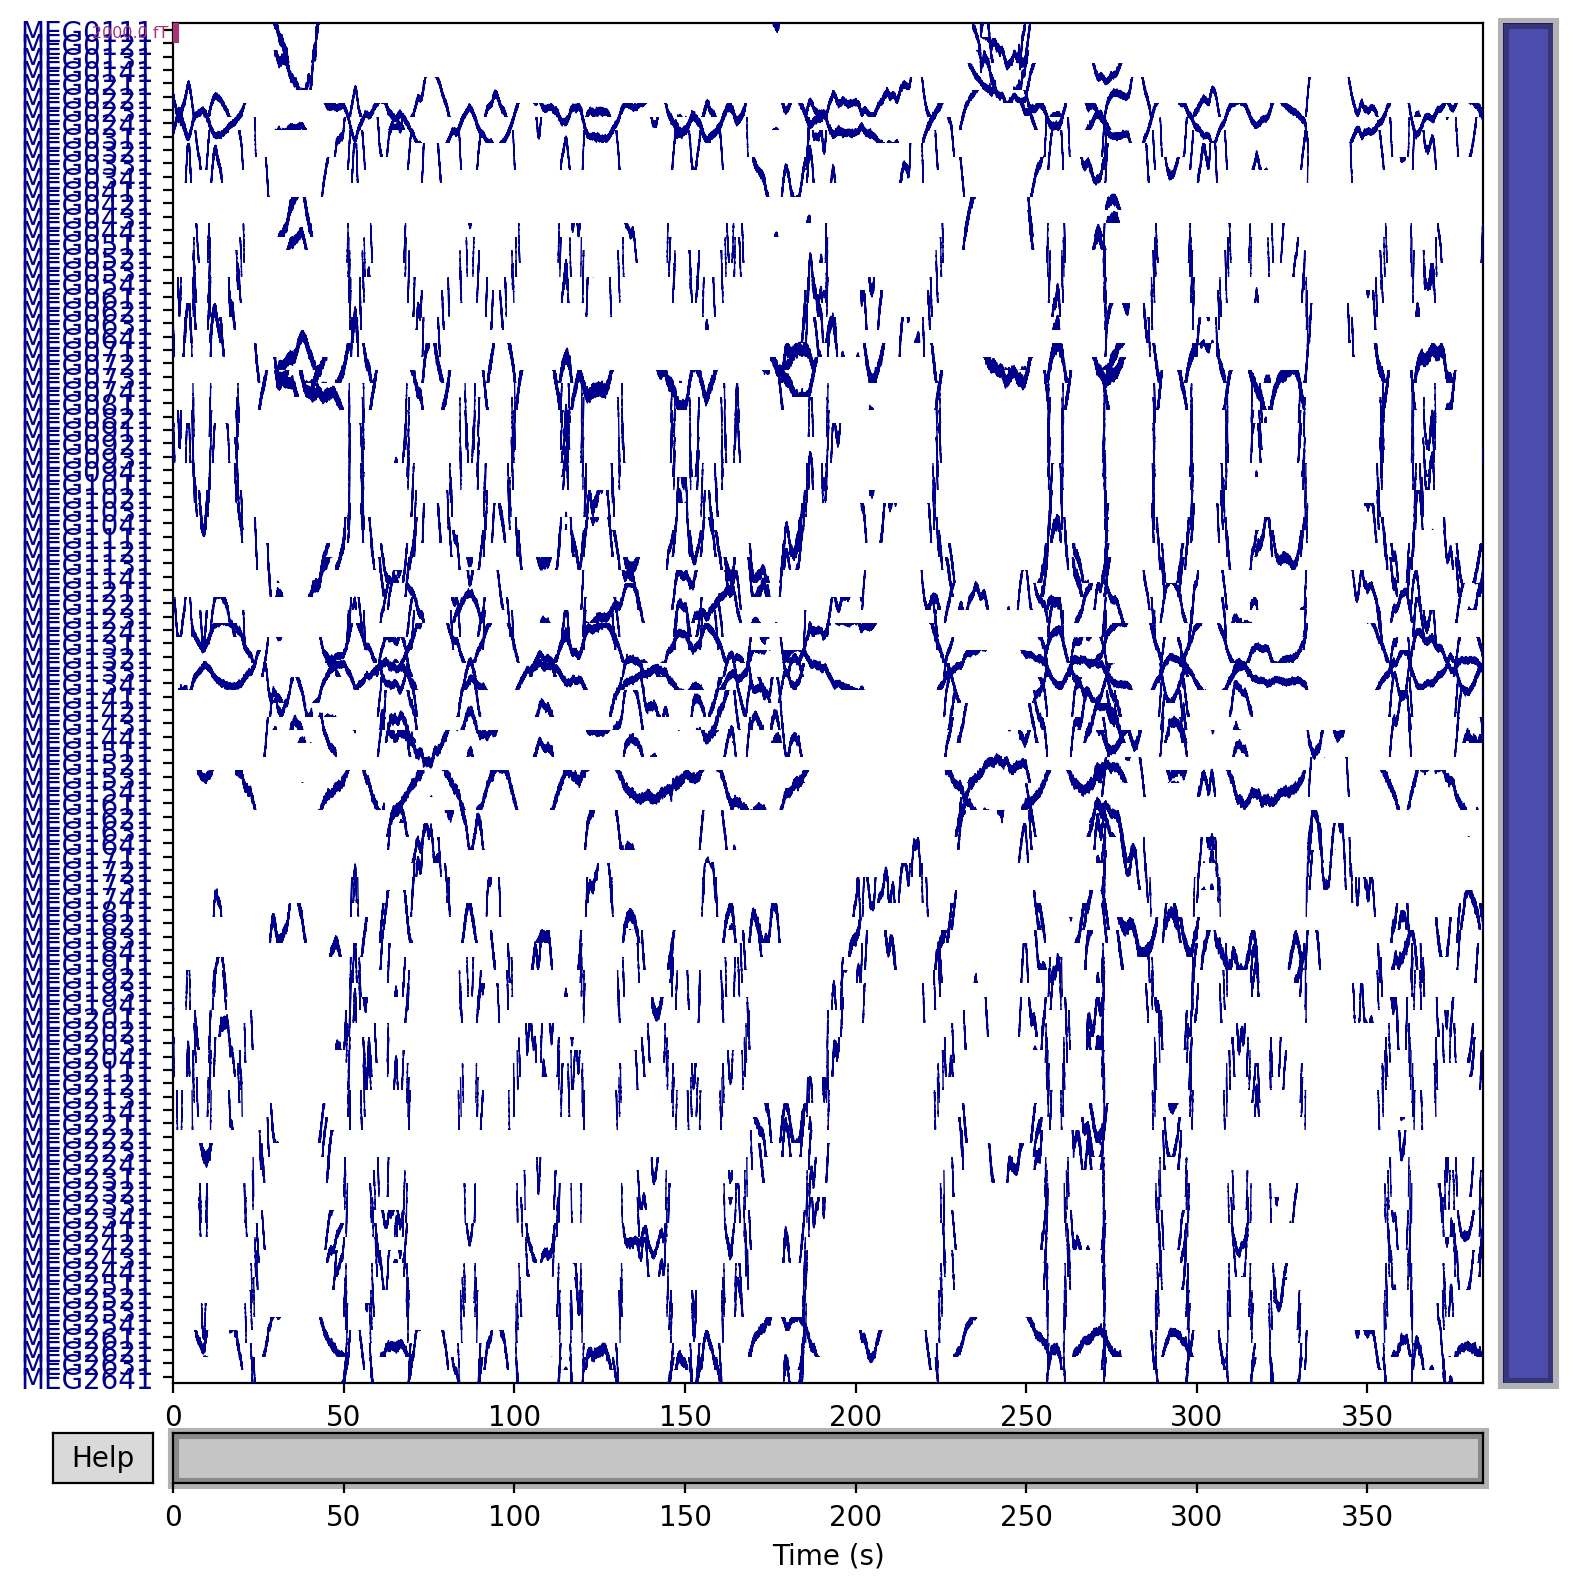

In [ ]:
mag_channels = mne.pick_types(raw.info, meg="mag")
raw.plot(duration=600, order=mag_channels, n_channels=len(mag_channels), remove_dc=False)

In [ ]:
fig = raw.compute_psd(tmax=np.inf, fmax=250).plot(
    average=True, amplitude=False, picks="data", exclude="bads"
)
# add some arrows at 60 Hz and its harmonics:
for ax in fig.axes[1:]:
    freqs = ax.lines[-1].get_xdata()
    psds = ax.lines[-1].get_ydata()
    for freq in (60, 120, 180, 240):
        idx = np.searchsorted(freqs, freq)
        ax.arrow(
            x=freqs[idx],
            y=psds[idx] + 18,
            dx=0,
            dy=-12,
            color="red",
            width=0.1,
            head_width=3,
            length_includes_head=True,
        )   

Effective window size : 2.048 (s)


In [ ]:
ecg_epochs = mne.preprocessing.create_ecg_epochs(raw)
ecg_epochs.plot_image(combine="mean")

Reconstructing ECG signal from Magnetometers
Setting up band-pass filter from 8 - 16 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 8.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 7.75 Hz)
- Upper passband edge: 16.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 16.25 Hz)
- Filter length: 10000 samples (10.000 s)

Number of ECG events detected : 569 (average pulse 88 / min.)
Not setting metadata
569 matching events found
No baseline correction applied
Using data from preloaded Raw for 569 events and 1001 original time points ...
1 bad epochs dropped
Not setting metadata
568 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
568 matching events found
No baseline correction applied
0 projection items activated
combining chann

[<Figure size 1280x960 with 3 Axes>, <Figure size 1280x960 with 3 Axes>]

In [ ]:
avg_ecg_epochs = ecg_epochs.average().apply_baseline((-0.5, -0.2))

Applying baseline correction (mode: mean)


In [ ]:
avg_ecg_epochs.plot_joint(times=[-0.25, -0.025, 0, 0.025, 0.25])

No projector specified for this dataset. Please consider the method self.add_proj.


[<Figure size 1600x840 with 8 Axes>, <Figure size 1600x840 with 8 Axes>]

In [ ]:
eog_epochs = mne.preprocessing.create_eog_epochs(raw, baseline=(-0.5, -0.2))
eog_epochs.plot_image(combine="mean")
eog_epochs.average().plot_joint()

RuntimeError: No EOG channel(s) found

## triggers

In [8]:
raw.first_samp, raw.info["sfreq"], raw.times[0], raw.times[-1]

(529000, 1000.0, 0.0, 383.999)

In [3]:
sfreq = raw.info["sfreq"]
sfreq

1000.0

In [28]:
events = mne.find_events(raw, stim_channel='STI101')
events = pd.DataFrame(events, columns = ["sample_index", "zero", "event_code"])
sfreq = raw.info["sfreq"]
events["event_times(s)"] = (events["sample_index"] - raw.first_samp) / sfreq
events["trigger_duration(ms)"] = events["event_times(s)"].diff()*1000
events

Finding events on: STI101
225 events found on stim channel STI101
Event IDs: [ 96 128 129 130 131 132 133 134 135 144 255]


,sample_index,zero,event_code,event_times(s),trigger_duration(ms)
0,544918,0,255,15.918,NaN
1,548011,0,128,19.011,3093.0
2,548680,0,129,19.680,669.0
3,549688,0,144,20.688,1008.0
4,555960,0,96,26.960,6272.0
...,...,...,...,...,...
220,889498,0,133,360.498,1501.0
221,890999,0,134,361.999,1501.0
222,892517,0,135,363.517,1518.0
223,893535,0,144,364.535,1018.0


In [40]:
events["event_code"].unique()

array([255, 128, 129, 144,  96, 130, 131, 132, 133, 134, 135])

In [ ]:
events["trigger_duration(ms)"][events["event_code"]==129]

,sample_index,zero,event_code,event_times(s),trigger_duration(ms)
2,548680,0,129,19.680,669.0
6,558088,0,129,29.088,669.0
10,570471,0,129,41.471,667.0
14,577252,0,129,48.252,667.0
22,591280,0,129,62.280,667.0
28,608120,0,129,79.120,668.0
32,613691,0,129,84.691,667.0
40,624166,0,129,95.166,667.0
50,641022,0,129,112.022,667.0
54,649096,0,129,120.096,668.0


In [47]:
for triggercode in events["event_code"].unique() : 
    plt.figure()
    x = events["trigger_duration(ms)"][1:,][events["event_code"]==triggercode]
    plt.hist(x)
    plt.title(f"histogramme des triggers pour trigger {triggercode}")
    plt.xlabel("temps (ms)")
    plt.show()

In [ ]:
event_ids = sorted(events["event_code"].unique())

# créer un mapping position -> event id
y_pos = np.arange(len(event_ids))
mapping = dict(zip(event_ids, y_pos))

plt.figure(figsize=(12,6))
plt.grid(alpha = 0.4)

for event_id in event_ids:

    subset = events[events["event_code"] == event_id]

    plt.scatter(
        subset["event_times(s)"],
        [mapping[event_id]] * len(subset),
        label=f"id:{event_id}; N:{len(subset)}"
    )

plt.xlabel("Time (s)")
plt.ylabel("Event id")

# afficher les vrais labels
plt.yticks(y_pos, event_ids)
plt.show()

In [18]:
from collections import Counter
Counter(events["event_code"])

Counter({128: 32,
         129: 32,
         144: 32,
         96: 32,
         130: 24,
         131: 24,
         132: 16,
         133: 16,
         134: 8,
         135: 8,
         255: 1})

In [17]:
plt.hist(events["trigger_duration"], bins=50)

(array([ 32.,  33.,   5.,  14., 111.,   8.,   2.,   3.,   0.,   2.,   0.,
          0.,   1.,   1.,   1.,   1.,   0.,   2.,   0.,   0.,   1.,   1.,
          1.,   0.,   0.,   0.,   1.,   0.,   1.,   1.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,
          0.,   0.,   0.,   0.,   0.,   1.]),
 array([ 0.667  ,  0.86468,  1.06236,  1.26004,  1.45772,  1.6554 ,
         1.85308,  2.05076,  2.24844,  2.44612,  2.6438 ,  2.84148,
         3.03916,  3.23684,  3.43452,  3.6322 ,  3.82988,  4.02756,
         4.22524,  4.42292,  4.6206 ,  4.81828,  5.01596,  5.21364,
         5.41132,  5.609  ,  5.80668,  6.00436,  6.20204,  6.39972,
         6.5974 ,  6.79508,  6.99276,  7.19044,  7.38812,  7.5858 ,
         7.78348,  7.98116,  8.17884,  8.37652,  8.5742 ,  8.77188,
         8.96956,  9.16724,  9.36492,  9.5626 ,  9.76028,  9.95796,
        10.15564, 10.35332, 10.551  ]),
 <BarContainer object of 50 artists>)